<a href="https://colab.research.google.com/github/Sonu-kumar-08/YBI-INTERNSHIP/blob/main/Student_Performance_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Student Performance Prediction - YbiFoundation Project


In [44]:
import pandas as pd
import numpy as np
import seaborn as sns
from google.colab import files

uploaded = files.upload()  # uploading csv file

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())

Saving Student_performance_data _.csv to Student_performance_data _ (2).csv
Dataset loaded successfully!
Rows and columns: (2392, 15)


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


In [45]:
print("Describe data")
df.describe()

Describe data


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


In [46]:
#Understand columns, data types
print("================Column names:===============")
print(df.columns.tolist())

print("===============Data types:============")
print(df.dtypes)

print("=========Dataset information:=============")
df.info()

================Column names:===============
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']
===============Data types:============
StudentID              int64
Age                    int64
Gender                 int64
Ethnicity              int64
ParentalEducation      int64
StudyTimeWeekly      float64
Absences               int64
Tutoring               int64
ParentalSupport        int64
Extracurricular        int64
Sports                 int64
Music                  int64
Volunteering           int64
GPA                  float64
GradeClass           float64
dtype: object
=========Dataset information:=============
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID     

In [47]:
#summary statistics
print("==============Summary statistics:===================")
display(df.describe(include="all").T)

==============Summary statistics:===================


,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.500000,690.655244,1001.000000,1598.750000,2196.500000,2794.250000,3392.000000
Age,2392.0,16.468645,1.123798,15.000000,15.000000,16.000000,17.000000,18.000000
Gender,2392.0,0.510870,0.499986,0.000000,0.000000,1.000000,1.000000,1.000000
Ethnicity,2392.0,0.877508,1.028476,0.000000,0.000000,0.000000,2.000000,3.000000
ParentalEducation,2392.0,1.746237,1.000411,0.000000,1.000000,2.000000,2.000000,4.000000
StudyTimeWeekly,2392.0,9.771992,5.652774,0.001057,5.043079,9.705363,14.408410,19.978094
Absences,2392.0,14.541388,8.467417,0.000000,7.000000,15.000000,22.000000,29.000000
Tutoring,2392.0,0.301421,0.458971,0.000000,0.000000,0.000000,1.000000,1.000000
ParentalSupport,2392.0,2.122074,1.122813,0.000000,1.000000,2.000000,3.000000,4.000000
Extracurricular,2392.0,0.383361,0.486307,0.000000,0.000000,0.000000,1.000000,1.000000


In [48]:
#Checking missing values and duplicates
print("======================Missing values per column:===================")
display(df.isnull().sum().to_frame("Missing values"))
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate StudentID values:", df["StudentID"].duplicated().sum())




======================Missing values per column:===================


,Missing values
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


Exact duplicate rows: 0
Duplicate StudentID values: 0


In [49]:
# Making a cleaned copy of it
clean_df = df.drop_duplicates().copy()
print("Shape before cleaning:", df.shape)
print("Shape after removing exact duplicate rows:", clean_df.shape)


Shape before cleaning: (2392, 15)
Shape after removing exact duplicate rows: (2392, 15)


In [50]:
#Checking ranges and counting category
print("==============GradeClass values and counts:==============")
display(clean_df["GradeClass"].value_counts(dropna=False).sort_index().to_frame("Count"))

print("==============Gender codes:==============")
display(clean_df["Gender"].value_counts(dropna=False).sort_index().to_frame("Count"))

print("==============Numeric ranges:==============")
display(clean_df[["Age", "StudyTimeWeekly", "Absences", "GPA", "GradeClass"]].describe().T)



==============GradeClass values and counts:==============


,Count
GradeClass,
0.0,107
1.0,269
2.0,391
3.0,414
4.0,1211


==============Gender codes:==============


,Count
Gender,
0,1170
1,1222


==============Numeric ranges:==============


,count,mean,std,min,25%,50%,75%,max
Age,2392.0,16.468645,1.123798,15.000000,15.000000,16.000000,17.000000,18.000000
StudyTimeWeekly,2392.0,9.771992,5.652774,0.001057,5.043079,9.705363,14.408410,19.978094
Absences,2392.0,14.541388,8.467417,0.000000,7.000000,15.000000,22.000000,29.000000
GPA,2392.0,1.906186,0.915156,0.000000,1.174803,1.893393,2.622216,4.000000
GradeClass,2392.0,2.983696,1.233908,0.000000,2.000000,4.000000,4.000000,4.000000


In [51]:
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


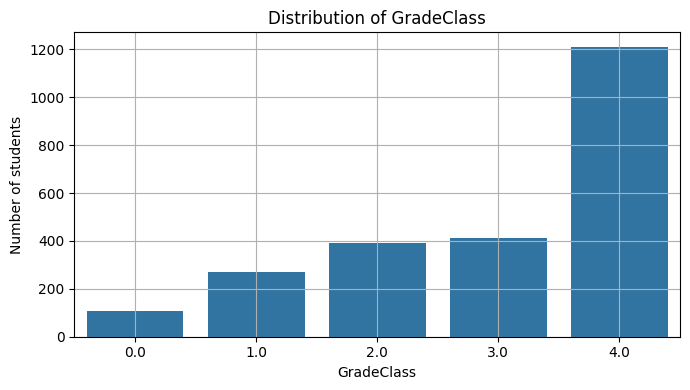

In [52]:
#Exploreing the target variable
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
sns.countplot(data=clean_df, x="GradeClass")
plt.title("Distribution of GradeClass")
plt.xlabel("GradeClass")
plt.ylabel("Number of students")
plt.tight_layout()
plt.grid()
plt.show()

In [53]:
print("Target proportions (%):")
display((clean_df["GradeClass"].value_counts(normalize=True).sort_index() * 100)
        .round(2).to_frame("Percent"))


Target proportions (%):


,Percent
GradeClass,
0.0,4.47
1.0,11.25
2.0,16.35
3.0,17.31
4.0,50.63


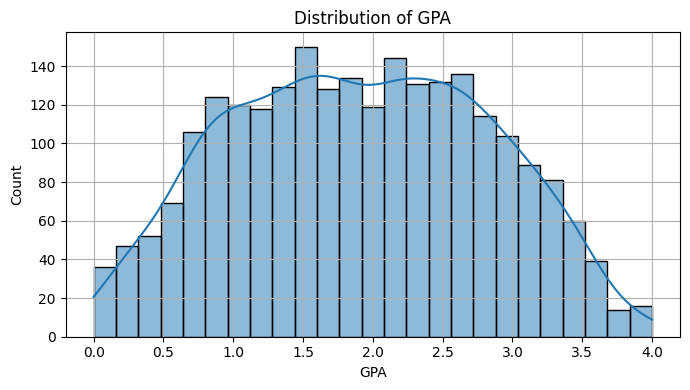

In [54]:
#analyze gpa
plt.figure(figsize=(7, 4))
sns.histplot(clean_df["GPA"], bins=25, kde=True)
plt.title("Distribution of GPA")
plt.xlabel("GPA")
plt.tight_layout()
plt.grid()
plt.show()





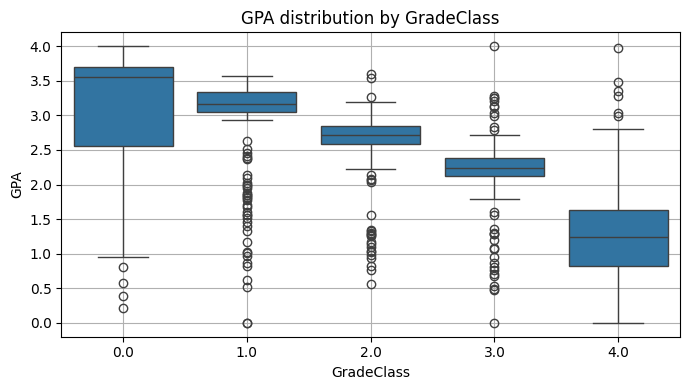

In [55]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=clean_df, x="GradeClass", y="GPA")
plt.title("GPA distribution by GradeClass")
plt.tight_layout()
plt.grid()
plt.show()

In [56]:

display(clean_df.groupby("GradeClass")["GPA"].agg(["count", "mean", "median", "min", "max"]).round(2))

,count,mean,median,min,max
GradeClass,,,,,
0.0,107,3.10,3.55,0.21,4.00
1.0,269,3.00,3.17,0.00,3.57
2.0,391,2.66,2.71,0.56,3.60
3.0,414,2.22,2.24,0.00,4.00
4.0,1211,1.21,1.25,0.00,3.98


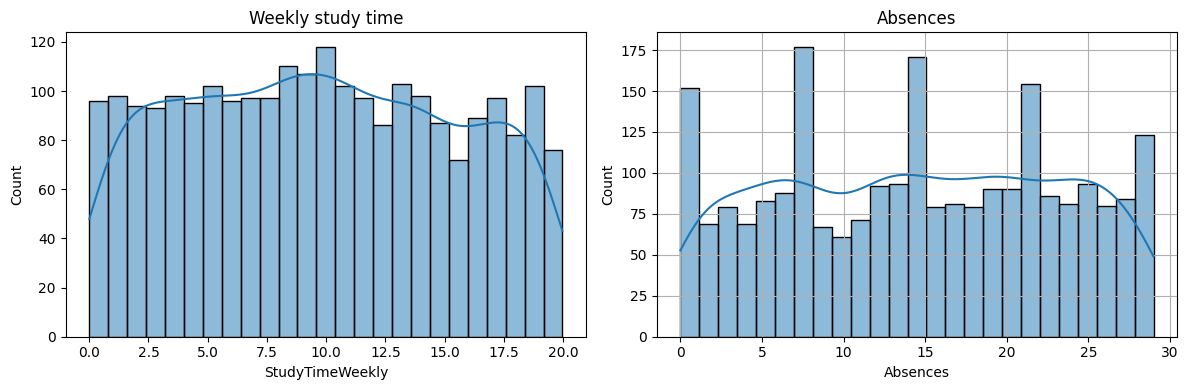

In [57]:
#Exploreing study time and absences
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(clean_df["StudyTimeWeekly"], bins=25, kde=True, ax=axes[0])

axes[0].set_title("Weekly study time")
sns.histplot(clean_df["Absences"], bins=25, kde=True, ax=axes[1])
axes[1].set_title("Absences")
plt.tight_layout()
plt.grid()
plt.show()

In [58]:
display(clean_df.groupby("GradeClass")[["StudyTimeWeekly", "Absences"]].mean().round(2))

,StudyTimeWeekly,Absences
GradeClass,,
0.0,11.85,5.75
1.0,11.12,5.31
2.0,10.11,7.25
3.0,9.76,11.43
4.0,9.18,20.79


In [59]:
#Compareing tutoring, parental support, and some activities
for col in ["Tutoring", "ParentalSupport", "Extracurricular", "Sports", "Music", "Volunteering"]:
    print(f"\\nAverage GPA by {col}:")
    display(clean_df.groupby(col)["GPA"].mean().round(2).to_frame("Average GPA"))

\nAverage GPA by Tutoring:


,Average GPA
Tutoring,
0,1.82
1,2.11


\nAverage GPA by ParentalSupport:


,Average GPA
ParentalSupport,
0,1.54
1,1.76
2,1.88
3,2.04
4,2.19


\nAverage GPA by Extracurricular:


,Average GPA
Extracurricular,
0,1.84
1,2.02


... (2 outputs left out)

\nAverage GPA by Music:


,Average GPA
Music,
0,1.87
1,2.04


\nAverage GPA by Volunteering:


,Average GPA
Volunteering,
0,1.90
1,1.91


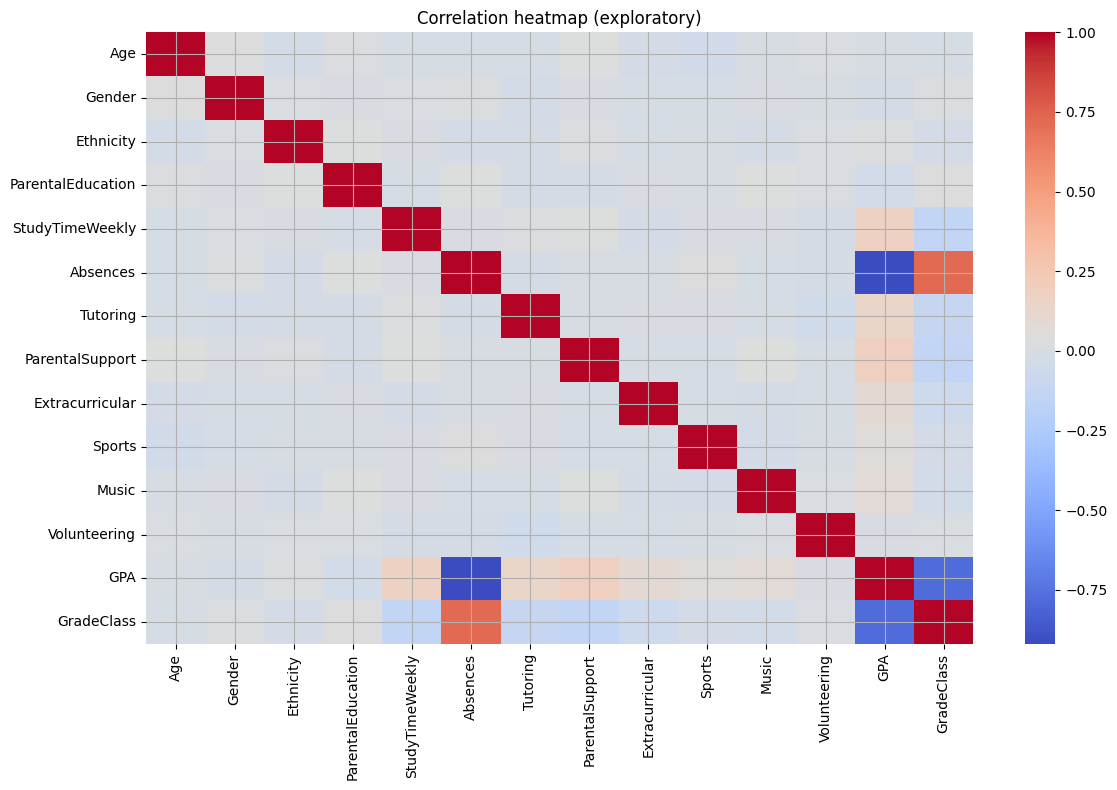

Reminder: correlation does not prove causation.


In [60]:
# Correlation analysis for numeric columns
numeric_df = clean_df.select_dtypes(include="number").drop(columns=["StudentID"], errors="ignore")
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", annot=False)
plt.title("Correlation heatmap (exploratory)")
plt.tight_layout()
plt.grid()
plt.show()
print("Reminder: correlation does not prove causation.")

In [61]:
#Separated input data and output data so we can train our model.
from sklearn.model_selection import train_test_split
# Selecting input columns
X = clean_df[['Age', 'Gender', 'Ethnicity',
              'ParentalEducation', 'StudyTimeWeekly',
              'Absences', 'Tutoring', 'ParentalSupport',
              'Extracurricular', 'Sports', 'Music',
              'Volunteering']]

# Selecting output column
y = clean_df['GradeClass']

# Splitting the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1913, 12)
Testing data: (479, 12)


In [62]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = clean_df[['Age', 'StudyTimeWeekly', 'Absences',
              'ParentalSupport', 'Tutoring']]

y = clean_df['GPA']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [63]:
model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print("------Actual GPA:------")
print(y_test.head())
print("---------Predicted GPA:--------")
print(predictions[:5])

------Actual GPA:------
1004    1.427724
196     3.117354
2342    2.037769
1708    3.548521
435     0.248977
Name: GPA, dtype: float64
---------Predicted GPA:--------
[1.30556185 2.88596322 1.95686755 3.46864532 0.22093143]


In [64]:
print("-----------Mean Absolute Error----------:", mean_absolute_error(y_test, predictions))
print("-------Mean Squared Error----------:", mean_squared_error(y_test, predictions))
print("-------R2 Score:-------", r2_score(y_test, predictions))

-----------Mean Absolute Error----------: 0.1875491700681223
-------Mean Squared Error----------: 0.059542207236777965
-------R2 Score:------- 0.9279963007547849


In [71]:
from sklearn.model_selection import train_test_split

# Ensure we define inputs X and target y (GradeClass) for classification
X = clean_df[['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering']]
y = clean_df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).sort_index().round(3).to_frame("Proportion"))
print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).sort_index().round(3).to_frame("Proportion"))

Training rows: 1913
Testing rows: 479

Training target distribution:


,Proportion
GradeClass,
0.0,0.045
1.0,0.112
2.0,0.164
3.0,0.173
4.0,0.506



Testing target distribution:


,Proportion
GradeClass,
0.0,0.044
1.0,0.113
2.0,0.163
3.0,0.173
4.0,0.507


In [74]:
#Trained a Random Forest classification pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Define the categorical and numeric features
categorical_features = ['Gender', 'Ethnicity', 'ParentalEducation', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering']
numeric_features = ['Age', 'StudyTimeWeekly', 'Absences']

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features),
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]), numeric_features)
    ]
)

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        min_samples_leaf=2
    ))
])

rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)
print("Random Forest model trained.")

Random Forest model trained.


In [75]:
 #Evaluate the model properly
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report

print("-----------Accuracy:----------", round(accuracy_score(y_test, rf_predictions), 4))
print("-----------Balanced accuracy-----------:", round(balanced_accuracy_score(y_test, rf_predictions), 4))
print("---------Macro F1:-------", round(f1_score(y_test, rf_predictions, average="macro"), 4))
print("\nClassification report:")
print(classification_report(y_test, rf_predictions, zero_division=0))

-----------Accuracy:---------- 0.6889
-----------Balanced accuracy-----------: 0.5129
---------Macro F1:------- 0.5174

Classification report:
              precision    recall  f1-score   support

         0.0       0.31      0.19      0.24        21
         1.0       0.49      0.43      0.46        54
         2.0       0.47      0.58      0.52        78
         3.0       0.48      0.47      0.47        83
         4.0       0.90      0.90      0.90       243

    accuracy                           0.69       479
   macro avg       0.53      0.51      0.52       479
weighted avg       0.69      0.69      0.69       479



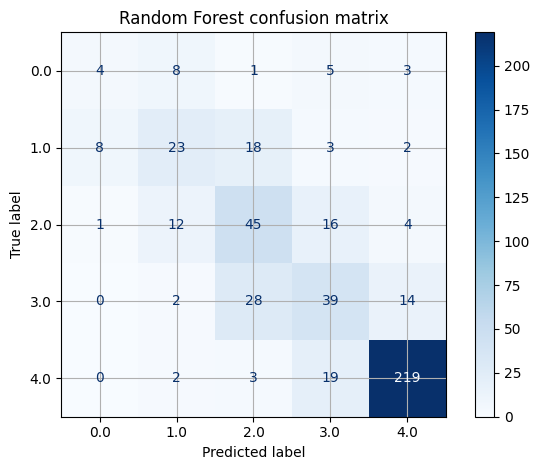

In [77]:
#Confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = sorted(y.unique())
cm = confusion_matrix(y_test, rf_predictions, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest confusion matrix")
plt.tight_layout()
plt.grid()
plt.show()

In [78]:
#Comparing Models
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import precision_score, recall_score
import pandas as pd

# Train a simple dummy classifier for baseline
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)
baseline_predictions = dummy_model.predict(X_test)

log_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])
log_model.fit(X_train, y_train)
log_predictions = log_model.predict(X_test)

comparison = pd.DataFrame([
    {
        "Model": "Most frequent baseline",
        "Accuracy": accuracy_score(y_test, baseline_predictions),
        "Balanced accuracy": balanced_accuracy_score(y_test, baseline_predictions),
        "Macro F1": f1_score(y_test, baseline_predictions, average="macro")
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, log_predictions),
        "Balanced accuracy": balanced_accuracy_score(y_test, log_predictions),
        "Macro F1": f1_score(y_test, log_predictions, average="macro")
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_predictions),
        "Balanced accuracy": balanced_accuracy_score(y_test, rf_predictions),
        "Macro F1": f1_score(y_test, rf_predictions, average="macro")
    }
]).round(4).sort_values("Macro F1", ascending=False)

display(comparison)

,Model,Accuracy,Balanced accuracy,Macro F1
2,Random Forest,0.6889,0.5129,0.5174
1,Logistic Regression,0.5866,0.4681,0.4448
0,Most frequent baseline,0.5073,0.2000,0.1346


In [79]:
# Now i am takeing an example values. These are not a real student's details.
feature_columns = ['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering']

new_student = pd.DataFrame([{
    "Age": 16,
    "Gender": 0,
    "Ethnicity": 0,
    "ParentalEducation": 2,
    "StudyTimeWeekly": 12.0,
    "Absences": 5,
    "Tutoring": 1,
    "ParentalSupport": 2,
    "Extracurricular": 1,
    "Sports": 0,
    "Music": 0,
    "Volunteering": 0
}])[feature_columns]

predicted_class = rf_model.predict(new_student)[0]
print("Predicted GradeClass:", predicted_class)

if hasattr(rf_model.named_steps["classifier"], "predict_proba"):
    probabilities = rf_model.predict_proba(new_student)[0]
    probability_table = pd.DataFrame({
        "GradeClass": rf_model.named_steps["classifier"].classes_,
        "Probability": probabilities
    }).sort_values("Probability", ascending=False)
    display(probability_table)

Predicted GradeClass: 1.0


,GradeClass,Probability
1,1.0,0.492094
2,2.0,0.297952
3,3.0,0.083961
0,0.0,0.064084
4,4.0,0.061908


In [81]:
#Final Run
import os
import joblib
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Final summary metrics for the selected Random Forest model.
final_metrics = {
    "accuracy": float(accuracy_score(y_test, rf_predictions)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, rf_predictions)),
    "macro_f1": float(f1_score(y_test, rf_predictions, average="macro"))
}
print("Final test metrics:")
for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")

# Extract and build feature importance dataframe
importances = rf_model.named_steps["classifier"].feature_importances_
# One-hot encoding creates more feature columns, let's map importances to mapped feature names
ohe_cols = rf_model.named_steps["preprocessor"].named_transformers_["categorical"].named_steps["onehot"].get_feature_names_out(categorical_features)
feature_names = list(ohe_cols) + numeric_features
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

# Save model and a results table.
os.makedirs("artifacts", exist_ok=True)
joblib.dump(rf_model, "artifacts/student_gradeclass_model.joblib")
comparison.to_csv("artifacts/model_comparison.csv", index=False)
importance_df.to_csv("artifacts/feature_importance.csv", index=False)

print("\nSaved files:")
print("- artifacts/student_gradeclass_model.joblib")
print("- artifacts/model_comparison.csv")
print("- artifacts/feature_importance.csv")

Final test metrics:
accuracy: 0.6889
balanced_accuracy: 0.5129
macro_f1: 0.5174

Saved files:
- artifacts/student_gradeclass_model.joblib
- artifacts/model_comparison.csv
- artifacts/feature_importance.csv
